In [19]:
with open(OUT / "results.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=str)
print("All done. Results saved in", OUT)

All done. Results saved in c:\Users\Gurnoor Kaur\Desktop\air-quality\outputs


In [18]:
import statsmodels.api as sm

m = df.assign(poor=(df["AQI"] >= POOR_LIMIT).astype(int),
              ym=df["Date"].dt.to_period("M"))
counts_m = (m.groupby(["City", "ym"])
              .agg(poor_days=("poor", "sum"), days=("poor", "size"), pm25=("PM2.5", "mean"))
              .reset_index())
counts_m["month"] = counts_m["ym"].dt.month
counts_m["winter"] = counts_m["month"].isin([11, 12, 1, 2]).astype(int)
counts_m["monsoon"] = counts_m["month"].isin([6, 7, 8, 9]).astype(int)
counts_m["year"] = counts_m["ym"].dt.year - 2015
city_level = counts_m.groupby("City")["pm25"].transform("mean")
counts_m["city_pm25_z"] = (city_level - city_level.mean()) / city_level.std()

Xp = sm.add_constant(counts_m[["winter", "monsoon", "year", "city_pm25_z"]])
poisson = sm.GLM(counts_m["poor_days"], Xp, family=sm.families.Poisson(),
                 offset=np.log(counts_m["days"])).fit()
print(poisson.summary().tables[1])
rate_ratio = np.exp(poisson.params).round(3)
print("\nRate ratios (x times more Poor days):\n", rate_ratio)
RESULTS["poisson"] = {"rate_ratio": rate_ratio.to_dict(),
                      "pvalues": poisson.pvalues.round(4).to_dict(),
                      "deviance_ratio": round(float(poisson.deviance / poisson.df_resid), 2),
                      "monthly_counts": counts_m.groupby("month")["poor_days"].mean().round(2).to_dict()}

                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -1.3959      0.034    -41.106      0.000      -1.462      -1.329
winter          0.6147      0.027     22.525      0.000       0.561       0.668
monsoon        -0.8062      0.041    -19.808      0.000      -0.886      -0.726
year           -0.1261      0.008    -15.446      0.000      -0.142      -0.110
city_pm25_z     0.6962      0.012     55.717      0.000       0.672       0.721

Rate ratios (x times more Poor days):
 const          0.248
winter         1.849
monsoon        0.447
year           0.881
city_pm25_z    2.006
dtype: float64


## Bonus 2: Poisson Regression: How Many Poor Days per Month?
A **count** (0–31 Poor days in a month) calls for a **Poisson GLM**, not linear regression. We add `offset = log(days observed)` because some months have fewer recorded days.
Read **rate ratios** = exp(coefficient): for example, winter = 2.3 means winter months have 2.3× as many Poor days. If deviance/df is much larger than 1, the data is **over-dispersed**, and a **Negative Binomial** model is the next step.

c:\Users\Gurnoor Kaur\Desktop\air-quality\venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting seasonal moving average Using zeros as starting parameters.
  start_params = self.start_params


Delhi monthly PM2.5, 12-month test MAE: {'SARIMA': 24.6, 'Exponential smoothing': 19.1}


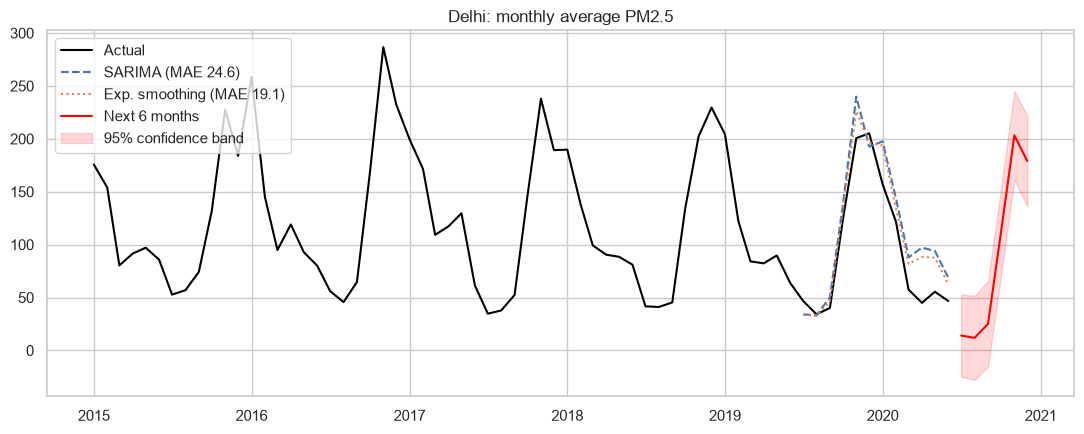

In [17]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

CITY_TS = "Delhi" if "Delhi" in df["City"].unique() else df["City"].value_counts().index[0]
monthly = (df[df["City"] == CITY_TS].set_index("Date")["PM2.5"]
             .resample("MS").mean().interpolate())
monthly = monthly[monthly.index < "2020-07-01"]
ts_train, ts_test = monthly[:-12], monthly[-12:]

sarima = SARIMAX(ts_train, order=(1, 0, 1), seasonal_order=(1, 1, 1, 12)).fit(disp=False)
hw = ExponentialSmoothing(ts_train, trend="add", seasonal="add", seasonal_periods=12).fit()
f_sarima_res = sarima.get_forecast(12)
f_sarima, ci_test = f_sarima_res.predicted_mean, f_sarima_res.conf_int()
f_hw = hw.forecast(12)
mae = {"SARIMA": float(np.mean(np.abs(f_sarima.values - ts_test.values))),
       "Exponential smoothing": float(np.mean(np.abs(f_hw.values - ts_test.values)))}
print(f"{CITY_TS} monthly PM2.5, 12-month test MAE:", {k: round(v, 1) for k, v in mae.items()})

future = SARIMAX(monthly, order=(1, 0, 1), seasonal_order=(1, 1, 1, 12)).fit(disp=False).get_forecast(6)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(monthly, label="Actual", color="black")
ax.plot(f_sarima, "--", label=f"SARIMA (MAE {mae['SARIMA']:.1f})")
ax.plot(f_hw, ":", label=f"Exp. smoothing (MAE {mae['Exponential smoothing']:.1f})")
ax.plot(future.predicted_mean, color="red", label="Next 6 months")
ci_future = future.conf_int()
ax.fill_between(ci_future.index, ci_future.iloc[:, 0], ci_future.iloc[:, 1], color="red", alpha=.15,
                label="95% confidence band")
ax.set_title(f"{CITY_TS}: monthly average PM2.5"); ax.legend()
save_fig(fig, "bonus_sarima")
RESULTS["timeseries"] = {
    "city": CITY_TS, "mae": {k: round(v, 2) for k, v in mae.items()},
    "actual": {str(k.date()): round(v, 2) for k, v in monthly.items()},
    "sarima_test": {str(k.date()): round(v, 2) for k, v in f_sarima.items()},
    "hw_test": {str(k.date()): round(v, 2) for k, v in f_hw.items()},
    "future": {str(k.date()): round(v, 2) for k, v in future.predicted_mean.items()},
    "future_lo": {str(k.date()): round(v, 2) for k, v in ci_future.iloc[:, 0].items()},
    "future_hi": {str(k.date()): round(v, 2) for k, v in ci_future.iloc[:, 1].items()},
    "test_lo": {str(k.date()): round(v, 2) for k, v in ci_test.iloc[:, 0].items()},
    "test_hi": {str(k.date()): round(v, 2) for k, v in ci_test.iloc[:, 1].items()},
}

## Bonus 1: Monthly PM2.5 Forecast (SARIMA vs Exponential Smoothing)
Delhi's monthly average PM2.5 has a **trend** and a strong **12-month seasonality** (winter peaks).
- **SARIMA(1,0,1)(1,1,1,12):** ARIMA plus a seasonal part that repeats every 12 months.
- **Holt-Winters exponential smoothing:** a weighted average in which recent months count more, with trend and season terms.
We hold out the last 12 months, compare the two models by **MAE** (mean absolute error), then forecast the next 6 months with a 95% confidence band.

Best alert threshold = 0.55 -> F1 0.853, recall 0.874


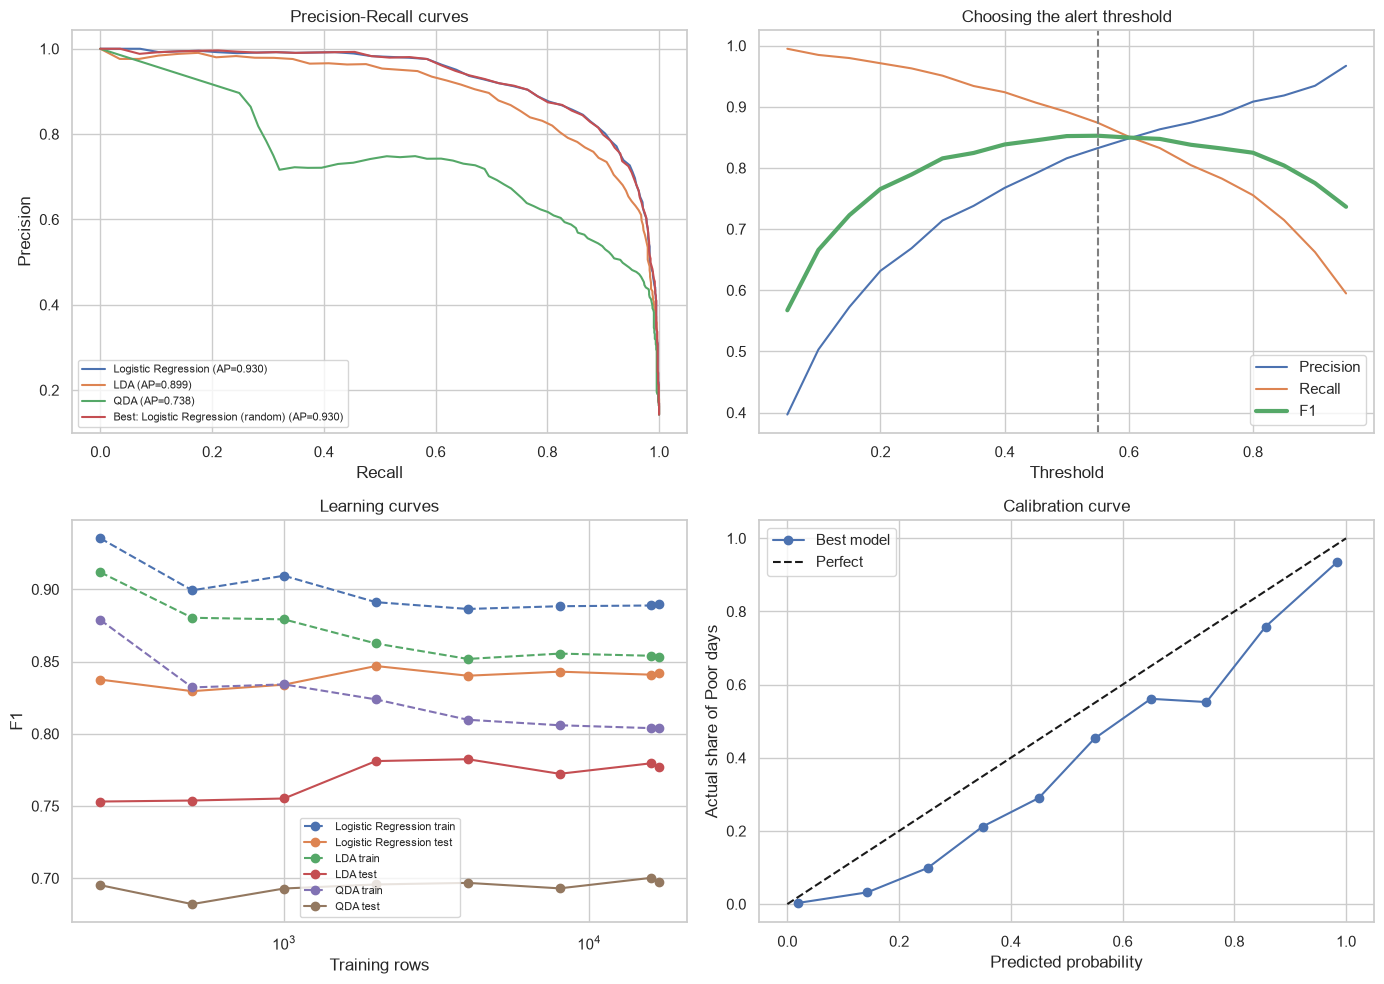

In [16]:
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.metrics import average_precision_score, precision_recall_curve

final_models = {**models, "Best: " + best_row["model"]: best_model}
prob_best = best_model.predict_proba(X_test)[:, 1]

pr_data = {}
for name, model in final_models.items():
    p = model.predict_proba(X_test)[:, 1]
    prec, rec, _ = precision_recall_curve(y_test, p)
    idx = np.linspace(0, len(prec) - 1, 200).astype(int)
    pr_data[name] = {"precision": prec[idx].round(4).tolist(), "recall": rec[idx].round(4).tolist(),
                     "ap": round(float(average_precision_score(y_test, p)), 4)}

thr_rows = []
for t in np.round(np.arange(0.05, 0.96, 0.05), 2):
    pred_t = (prob_best >= t).astype(int)
    thr_rows.append({"threshold": float(t), "precision": precision_score(y_test, pred_t, zero_division=0),
                     "recall": recall_score(y_test, pred_t), "f1": f1_score(y_test, pred_t)})
thr = pd.DataFrame(thr_rows).round(4)
best_thr = thr.loc[thr["f1"].idxmax()]
print(f"Best alert threshold = {best_thr['threshold']:.2f} -> F1 {best_thr['f1']:.3f}, "
      f"recall {best_thr['recall']:.3f}")

lc_data = {}
sizes = [n for n in [250, 500, 1000, 2000, 4000, 8000, 16000] if n < len(train)] + [len(train)]
for name in ["Logistic Regression", "LDA", "QDA"]:
    rows = {"size": [], "train": [], "val": []}
    for n in sizes:
        part = train.sample(n, random_state=0) if n < len(train) else train
        m = clone(models[name]).fit(part[FEATURES], part["target"])
        rows["size"].append(n)
        rows["train"].append(round(f1_score(part["target"], m.predict(part[FEATURES])), 4))
        rows["val"].append(round(f1_score(y_test, m.predict(X_test)), 4))
    lc_data[name] = rows

frac_pos, mean_pred = calibration_curve(y_test, prob_best, n_bins=10, strategy="uniform")

fig, ax = plt.subplots(2, 2, figsize=(14, 10))
for name, d in pr_data.items():
    ax[0, 0].plot(d["recall"], d["precision"], label=f"{name} (AP={d['ap']:.3f})")
ax[0, 0].set(title="Precision-Recall curves", xlabel="Recall", ylabel="Precision"); ax[0, 0].legend(fontsize=8)
ax[0, 1].plot(thr["threshold"], thr["precision"], label="Precision")
ax[0, 1].plot(thr["threshold"], thr["recall"], label="Recall")
ax[0, 1].plot(thr["threshold"], thr["f1"], label="F1", lw=3)
ax[0, 1].axvline(best_thr["threshold"], color="grey", ls="--")
ax[0, 1].set(title="Choosing the alert threshold", xlabel="Threshold"); ax[0, 1].legend()
for name, d in lc_data.items():
    ax[1, 0].plot(d["size"], d["train"], "o--", label=f"{name} train")
    ax[1, 0].plot(d["size"], d["val"], "o-", label=f"{name} test")
ax[1, 0].set(title="Learning curves", xlabel="Training rows", ylabel="F1", xscale="log")
ax[1, 0].legend(fontsize=8)
ax[1, 1].plot(mean_pred, frac_pos, "o-", label="Best model")
ax[1, 1].plot([0, 1], [0, 1], "k--", label="Perfect")
ax[1, 1].set(title="Calibration curve", xlabel="Predicted probability", ylabel="Actual share of Poor days")
ax[1, 1].legend()
save_fig(fig, "12_results_curves")

preds = test[["Date", "City", "AQI", "AQI_tomorrow", "target"]].copy()
for name, model in final_models.items():
    preds[name] = model.predict_proba(X_test)[:, 1].round(5)
preds.to_csv(OUT / "test_predictions.csv", index=False)

RESULTS["curves"] = {"pr": pr_data, "threshold": thr.to_dict(orient="records"),
                     "best_threshold": best_thr.to_dict(), "learning": lc_data,
                     "calibration": {"pred": mean_pred.round(4).tolist(), "actual": frac_pos.round(4).tolist()},
                     "best_name": "Best: " + best_row["model"]}

## Results Showcase: Curves
- **Precision-Recall curve + Average Precision (AP):** better than ROC when Poor days are rare.
- **Threshold curve:** the model outputs a probability, and *we* choose when to alert. A lower threshold catches more Poor days (recall ↑) but sends more false alarms (precision ↓). We pick the threshold with the best F1.
- **Learning curves:** train on 250 → all days and test on the unseen year. Rising test lines mean more data helps; a train-test gap means overfitting.
- **Calibration curve:** when the model says 70%, are about 70% of those days really Poor? Points near the diagonal mean the probabilities can be trusted.

In [15]:
all_scores = pd.DataFrame(
    [{"model": r["model"], "test_f1": r["f1"], "test_auc": r["auc"], "kind": "baseline"} for r in metric_rows] +
    [{"model": r["model"], "test_f1": r["test_f1"], "test_auc": r["test_auc"], "kind": "tuned"} for r in tune_rows])
best_row = all_scores.sort_values(["test_f1", "test_auc"], ascending=False).iloc[0]
lookup = {**models, **{k: v.best_estimator_ for k, v in tuned.items()}}
best_model = lookup[best_row["model"]]
print(all_scores.round(4).sort_values("test_f1", ascending=False).to_string(index=False))
print(f"\nBEST MODEL: {best_row['model']}  (test F1 = {best_row['test_f1']:.3f}, "
      f"AUC = {best_row['test_auc']:.3f})")

clf = best_model[-1]
importance = None
if hasattr(clf, "coef_"):
    importance = (pd.Series(np.ravel(clf.coef_), index=FEATURES)
                    .sort_values(key=np.abs, ascending=False).round(3))
    print("\nStrongest features (scaled coefficients):\n", importance.head(8))

joblib.dump({"model": best_model, "features": FEATURES, "name": best_row["model"]},
            OUT / "best_model.pkl")
RESULTS["conclusion"] = {
    "best_model": best_row["model"],
    "best_f1": round(float(best_row["test_f1"]), 4),
    "best_auc": round(float(best_row["test_auc"]), 4),
    "ranking": all_scores.round(4).sort_values("test_f1", ascending=False).to_dict(orient="records"),
    "importance": importance.to_dict() if importance is not None else {},
    "limitations": [
        "No weather data (wind speed, rain, temperature inversion) which strongly drives smog.",
        "Many values were missing and had to be filled in, which adds uncertainty.",
        "Stations are mostly in big cities, so results may not hold for rural areas.",
        "The test year includes the 2020 COVID lockdown, an unusual clean-air period.",
        "Only one day ahead; health planning often needs 3 to 7 day forecasts.",
    ],
}

                       model  test_f1  test_auc     kind
Logistic Regression (random)   0.8521    0.9849    tuned
  Logistic Regression (grid)   0.8505    0.9848    tuned
         Logistic Regression   0.8419    0.9850 baseline
                  LDA (grid)   0.8045    0.9822    tuned
                QDA (random)   0.7977    0.9745    tuned
                         LDA   0.7771    0.9793 baseline
                         QDA   0.6977    0.9496 baseline

BEST MODEL: Logistic Regression (random)  (test F1 = 0.852, AUC = 0.985)

Strongest features (scaled coefficients):
 PM2.5             2.466
AQI               2.188
AQI_roll7         1.155
CO                0.442
PM10              0.392
City_Ahmedabad    0.341
AQI_lag1         -0.246
City_Delhi        0.197
dtype: float64


## Stage 12: Conclusion
We rank every model (baseline + tuned) by **test F1**, use AUC to break ties, and save the winner to `outputs/best_model.pkl` for the app.
**Why the winner wins:** today's AQI and PM levels separate Poor and non-Poor days almost in a straight line, so a simple regularized linear model generalises best. QDA's extra flexibility only adds variance.
**Limitations:** no weather data (wind, rain), filled-in missing values, stations mostly in big cities, the 2020 COVID lockdown in the test year, and only a one-day-ahead forecast.

                                                        model  train_f1  test_f1     gap
0                                        Underfit: month only    0.3617   0.3587  0.0030
1      Overfit: degree-3 polynomial, almost no regularization    1.0000   0.7175  0.2825
2  Fixed: same polynomial + strong L2 regularization (C=0.01)    0.8865   0.8154  0.0711
3    Good fit: tuned logistic regression (full training data)    0.8924   0.8505  0.0419


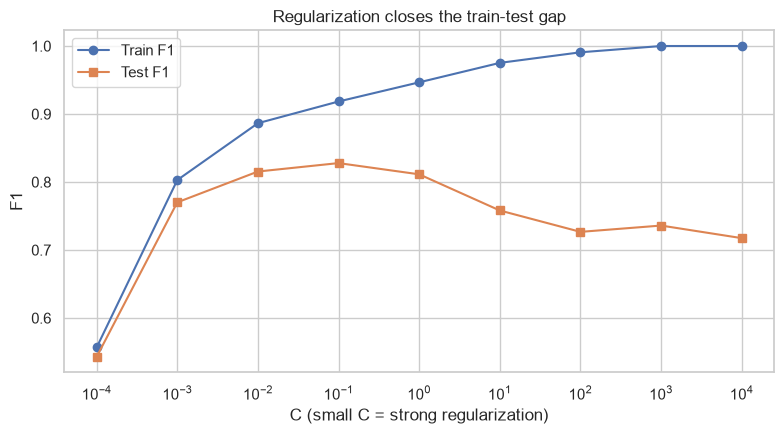

In [14]:
from sklearn.preprocessing import PolynomialFeatures

small = train.sample(1500, random_state=7)
fit_rows = []


def check(label, model, cols, X_tr=small, desc=""):
    model.fit(X_tr[cols], X_tr["target"])
    tr = f1_score(X_tr["target"], model.predict(X_tr[cols]))
    te = f1_score(y_test, model.predict(test[cols]))
    fit_rows.append({"model": label, "train_f1": tr, "test_f1": te, "gap": tr - te, "what": desc})


check("Underfit: month only", make_pipeline(StandardScaler(), LogisticRegression()),
      ["month_sin", "month_cos"], desc="Too simple: cannot see today's pollution at all")
check("Overfit: degree-3 polynomial, almost no regularization",
      make_pipeline(StandardScaler(), PolynomialFeatures(3), StandardScaler(),
                    LogisticRegression(C=1e4, max_iter=5000)),
      FEATURES, desc="Hundreds of feature combinations memorise the 1,500 training days")
check("Fixed: same polynomial + strong L2 regularization (C=0.01)",
      make_pipeline(StandardScaler(), PolynomialFeatures(3), StandardScaler(),
                    LogisticRegression(C=0.01, max_iter=5000)),
      FEATURES, desc="Regularization shrinks the weights, so the train-test gap closes")
check("Good fit: tuned logistic regression (full training data)", grid.best_estimator_,
      FEATURES, X_tr=train, desc="Simple model + enough data")
fit_table = pd.DataFrame(fit_rows).round(4)
print(fit_table[["model", "train_f1", "test_f1", "gap"]].to_string())

curve = []
for C in [1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100, 1e3, 1e4]:
    m = make_pipeline(StandardScaler(), PolynomialFeatures(3), StandardScaler(),
                      LogisticRegression(C=C, max_iter=5000)).fit(small[FEATURES], small["target"])
    curve.append({"C": C, "train_f1": f1_score(small["target"], m.predict(small[FEATURES])),
                  "test_f1": f1_score(y_test, m.predict(X_test))})
curve = pd.DataFrame(curve)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(curve["C"], curve["train_f1"], "o-", label="Train F1")
ax.plot(curve["C"], curve["test_f1"], "s-", label="Test F1")
ax.set_xscale("log"); ax.set_xlabel("C (small C = strong regularization)"); ax.set_ylabel("F1")
ax.set_title("Regularization closes the train-test gap"); ax.legend()
save_fig(fig, "11_regularization_curve")
RESULTS["fit"] = {"table": fit_table.to_dict(orient="records"),
                  "curve": curve.round(4).to_dict(orient="records")}

## Stage 11: Overfitting vs Underfitting
- **Underfitting:** the model is too simple, so it is bad on train AND test (month only: it can't see today's pollution).
- **Overfitting:** the model memorises the training data, so it is great on train and worse on test (degree-3 polynomial on only 1,500 days, almost no regularization).
- **Fix:** the same complex model with strong **L2 regularization** (C = 0.01) shrinks the weights, and the train-test gap closes.
The curve shows train and test F1 as C changes: on the left (strong regularization) the lines stay together, while on the right train shoots up and test falls.

In [13]:
from scipy.stats import loguniform, uniform
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

grid = GridSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, solver="liblinear")),
    param_grid={"logisticregression__C": [0.001, 0.01, 0.1, 1, 10, 100],
                "logisticregression__penalty": ["l1", "l2"],
                "logisticregression__class_weight": [None, "balanced"]},
    scoring="f1", cv=tscv, n_jobs=-1).fit(X_cv, y_cv)

rand = RandomizedSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, solver="liblinear")),
    param_distributions={"logisticregression__C": loguniform(1e-3, 1e2),
                         "logisticregression__penalty": ["l1", "l2"],
                         "logisticregression__class_weight": [None, "balanced"]},
    n_iter=25, scoring="f1", cv=tscv, random_state=42, n_jobs=-1).fit(X_cv, y_cv)

lda_grid = GridSearchCV(make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(solver="lsqr")),
                        {"lineardiscriminantanalysis__shrinkage": [None, 0.01, 0.1, 0.3, 0.5, "auto"]},
                        scoring="f1", cv=tscv).fit(X_cv, y_cv)
qda_rand = RandomizedSearchCV(make_pipeline(StandardScaler(), QuadraticDiscriminantAnalysis()),
                              {"quadraticdiscriminantanalysis__reg_param": uniform(0.0, 1.0)},
                              n_iter=20, scoring="f1", cv=tscv, random_state=42).fit(X_cv, y_cv)

tuned = {"Logistic Regression (grid)": grid, "Logistic Regression (random)": rand,
         "LDA (grid)": lda_grid, "QDA (random)": qda_rand}
tune_rows = []
for name, search in tuned.items():
    best = search.best_estimator_
    prob = best.predict_proba(X_test)[:, 1]
    tune_rows.append({"model": name, "best_params": {k.split("__")[1]: v for k, v in search.best_params_.items()},
                      "cv_f1": search.best_score_, "test_f1": f1_score(y_test, best.predict(X_test)),
                      "test_auc": roc_auc_score(y_test, prob)})
tune_table = pd.DataFrame(tune_rows)
print(tune_table.round(4).to_string())
RESULTS["tuning"] = json.loads(tune_table.round(4).to_json(orient="records"))

                          model                                                             best_params   cv_f1  test_f1  test_auc
0    Logistic Regression (grid)                 {'C': 0.1, 'class_weight': 'balanced', 'penalty': 'l1'}  0.8821   0.8505    0.9848
1  Logistic Regression (random)  {'C': 14.528246637516036, 'class_weight': 'balanced', 'penalty': 'l2'}  0.8820   0.8521    0.9849
2                    LDA (grid)                                                      {'shrinkage': 0.5}  0.8433   0.8045    0.9822
3                  QDA (random)                                       {'reg_param': 0.9507143064099162}  0.8295   0.7977    0.9745


## Stage 10: Hyperparameter Tuning (Grid Search + Random Search)
- **Grid search** tries **every** combination: 6 values of C × 2 penalties × 2 class weights = 24 combinations, each scored with 5-fold time-series CV.
- **Random search** tries **25 random** combinations from a range (C from 0.001 to 100 on a log scale). It is faster when there are many settings.
- `C` = 1 / regularization strength (small C = simpler model). `l1` can push useless weights to 0. `class_weight="balanced"` gives Poor days more importance.
- LDA (`shrinkage`) and QDA (`reg_param`) are tuned too, so the comparison is fair.

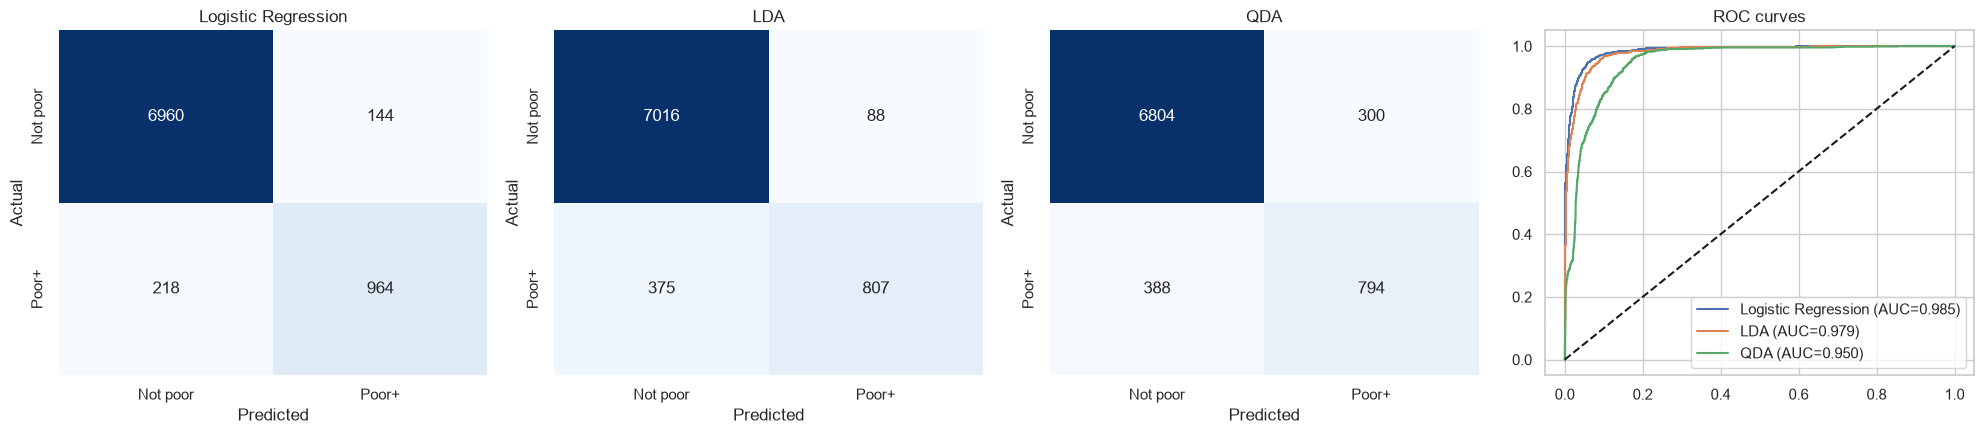

                 model  accuracy  precision  recall      f1     auc
0  Logistic Regression    0.9563     0.8700  0.8156  0.8419  0.9850
1                  LDA    0.9441     0.9017  0.6827  0.7771  0.9793
2                  QDA    0.9170     0.7258  0.6717  0.6977  0.9496


In [12]:
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)

metric_rows, roc_data, cms = [], {}, {}
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for i, (name, model) in enumerate(models.items()):
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    metric_rows.append({"model": name,
                        "accuracy": accuracy_score(y_test, pred),
                        "precision": precision_score(y_test, pred),
                        "recall": recall_score(y_test, pred),
                        "f1": f1_score(y_test, pred),
                        "auc": roc_auc_score(y_test, prob)})
    cm = confusion_matrix(y_test, pred)
    cms[name] = cm.tolist()
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[i],
                xticklabels=["Not poor", "Poor+"], yticklabels=["Not poor", "Poor+"])
    axes[i].set_title(name); axes[i].set_xlabel("Predicted"); axes[i].set_ylabel("Actual")
    fpr, tpr, _ = roc_curve(y_test, prob)
    idx = np.linspace(0, len(fpr) - 1, 200).astype(int)
    roc_data[name] = {"fpr": fpr[idx].round(4).tolist(), "tpr": tpr[idx].round(4).tolist()}
    axes[3].plot(fpr, tpr, label=f"{name} (AUC={metric_rows[-1]['auc']:.3f})")
axes[3].plot([0, 1], [0, 1], "k--"); axes[3].legend(); axes[3].set_title("ROC curves")
save_fig(fig, "09_confusion_roc")

metrics_table = pd.DataFrame(metric_rows).round(4)
print(metrics_table)
RESULTS["metrics"] = {"table": metrics_table.to_dict(orient="records"),
                      "confusion": cms, "roc": roc_data}

## Stage 9: Performance Metrics
Only about 1 in 5 days is Poor, so a model that always says "not poor" already gets ~80% accuracy and is useless. Better metrics:
- **Confusion matrix:** TN, FP (false alarm), FN (missed Poor day), TP.
- **Precision** = TP/(TP+FP): of our alerts, how many were right?
- **Recall** = TP/(TP+FN): of the real Poor days, how many did we catch?
- **F1** = the balance (harmonic mean) of precision and recall.
- **AUC-ROC:** the area under the curve of true-positive rate vs false-positive rate. 0.5 = coin flip, 1.0 = perfect.

In [11]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate

order = np.argsort(train["Date"].values, kind="stable")
X_cv, y_cv = X_train.iloc[order], y_train.iloc[order]
tscv = TimeSeriesSplit(n_splits=5)

cv_rows = []
for name, model in models.items():
    cv = cross_validate(model, X_cv, y_cv, cv=tscv, scoring=["f1", "roc_auc", "accuracy"])
    cv_rows.append({"model": name,
                    "cv_f1_mean": cv["test_f1"].mean(), "cv_f1_std": cv["test_f1"].std(),
                    "cv_auc_mean": cv["test_roc_auc"].mean(),
                    "cv_acc_mean": cv["test_accuracy"].mean(),
                    "fold_f1": list(np.round(cv["test_f1"], 3))})
cv_table = pd.DataFrame(cv_rows).round(3)
print(cv_table)
RESULTS["validation"] = {"method": "Chronological split at " + str(SPLIT_DATE.date()) +
                         " + TimeSeriesSplit(5) on the training years",
                         "table": cv_table.to_dict(orient="records")}

                 model  cv_f1_mean  cv_f1_std  cv_auc_mean  cv_acc_mean  \
0  Logistic Regression       0.878      0.040        0.978        0.934   
1                  LDA       0.826      0.052        0.971        0.913   
2                  QDA       0.764      0.058        0.943        0.875   

                               fold_f1  
0   [0.89, 0.912, 0.859, 0.917, 0.809]  
1   [0.849, 0.862, 0.81, 0.876, 0.732]  
2  [0.821, 0.783, 0.679, 0.824, 0.714]  


## Stage 8: Validation: Train-Test Split + Cross-Validation
We already have a **hold-out test set** (the future, from July 2019). For **cross-validation** we use `TimeSeriesSplit(5)`: fold 1 trains on the oldest data and validates on the next chunk, fold 2 trains on more, and so on. The model never trains on the future.
The **mean** CV score shows how good a model is; the **std** shows how stable it is.

In [10]:
from sklearn.discriminant_analysis import (LinearDiscriminantAnalysis,
                                           QuadraticDiscriminantAnalysis)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "LDA": make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()),
    # reg_param stops QDA from crashing on 0/1 columns with tiny variance
    "QDA": make_pipeline(StandardScaler(), QuadraticDiscriminantAnalysis(reg_param=0.1)),
}
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name:20s} trained. Test accuracy = {model.score(X_test, y_test):.3f}")

Logistic Regression  trained. Test accuracy = 0.956
LDA                  trained. Test accuracy = 0.944
QDA                  trained. Test accuracy = 0.917


## Stage 7: Modeling: Logistic Regression vs LDA vs QDA
- **Logistic Regression:** a weighted sum of features passed through the S-shaped sigmoid curve gives a probability from 0 to 1.
- **LDA (Linear Discriminant Analysis):** assumes both classes are bell curves with the **same** spread, so the boundary is a straight line.
- **QDA (Quadratic Discriminant Analysis):** each class has **its own** spread, so the boundary can curve. More flexible, but it overfits more easily.
`make_pipeline(StandardScaler(), model)` scales the data and then fits the model, in one object.

In [9]:
from sklearn.feature_selection import SelectKBest, f_classif

ENGINEERED = ["AQI", "AQI_lag1", "AQI_roll3", "AQI_roll7", "AQI_change", "PM_ratio",
              "month_sin", "month_cos", "is_weekend"]
CANDIDATES = POLLUTANTS + ENGINEERED + [c for c in fe.columns if c.startswith(("Season_", "City_"))]

SPLIT_DATE = pd.Timestamp("2019-07-01")
train = fe[fe["Date"] < SPLIT_DATE]
test = fe[fe["Date"] >= SPLIT_DATE]

corr_m = train[POLLUTANTS + ENGINEERED].corr().abs()
upper = corr_m.where(np.triu(np.ones(corr_m.shape, dtype=bool), k=1))
redundant = [c for c in upper.columns if (upper[c] > 0.95).any() and c != "AQI"]
candidates = [c for c in CANDIDATES if c not in redundant]

K = 15
selector = SelectKBest(f_classif, k=K).fit(train[candidates], train["target"])
scores = (pd.Series(selector.scores_, index=candidates).sort_values(ascending=False))
FEATURES = list(scores.head(K).index)
print("Removed as redundant:", redundant)
print("Selected features:", FEATURES)

X_train, y_train = train[FEATURES], train["target"]
X_test, y_test = test[FEATURES], test["target"]
print(f"Train: {len(train)} rows | Test: {len(test)} rows")

fe.to_csv(OUT / "features.csv", index=False)
RESULTS["features"] = {"engineered": ENGINEERED, "redundant_removed": redundant,
                       "selected": FEATURES, "scores": scores.round(1).head(25).to_dict(),
                       "train_rows": int(len(train)), "test_rows": int(len(test)),
                       "split_date": str(SPLIT_DATE.date()),
                       "target_share_train": round(float(y_train.mean()), 4),
                       "target_share_test": round(float(y_test.mean()), 4)}

Removed as redundant: ['AQI_roll3']
Selected features: ['AQI_roll7', 'AQI', 'PM2.5', 'AQI_lag1', 'PM10', 'NO', 'NOx', 'NO2', 'City_Ahmedabad', 'SO2', 'month_cos', 'Toluene', 'CO', 'City_Delhi', 'Season_Monsoon']
Train: 16946 rows | Test: 8286 rows


## Stage 6b: Feature Selection, Scaling & Train-Test Split
- **Split by date:** everything before 1 July 2019 is used for training, and everything after for testing. A random split would leak the future, because today's air looks like yesterday's.
- **Selection 1:** drop features that are near-copies of another one (correlation > 0.95).
- **Selection 2:** `SelectKBest` keeps the 15 features that best separate Poor and non-Poor days (ANOVA F-test).
- **Scaling:** `StandardScaler` (mean 0, std 1) sits inside each model and learns from the training data only.

In [8]:
fe = df.sort_values(["City", "Date"]).copy()
g = fe.groupby("City")

# TARGET: is TOMORROW's AQI 201 or more?
fe["AQI_tomorrow"] = g["AQI"].shift(-1)
next_date = g["Date"].shift(-1)
fe = fe[(next_date - fe["Date"]).dt.days == 1]
fe["target"] = (fe["AQI_tomorrow"] >= POOR_LIMIT).astype(int)

g = fe.groupby("City")
fe["AQI_lag1"] = g["AQI"].shift(1)
fe["AQI_roll3"] = g["AQI"].transform(lambda s: s.rolling(3).mean())
fe["AQI_roll7"] = g["AQI"].transform(lambda s: s.rolling(7).mean())
fe["AQI_change"] = fe["AQI"] - fe["AQI_lag1"]
fe["PM_ratio"] = fe["PM2.5"] / (fe["PM10"] + 1)
fe["month"] = fe["Date"].dt.month
fe["month_sin"] = np.sin(2 * np.pi * fe["month"] / 12)
fe["month_cos"] = np.cos(2 * np.pi * fe["month"] / 12)
fe["is_weekend"] = (fe["Date"].dt.dayofweek >= 5).astype(int)
fe["Season"] = fe["month"].map({12: "Winter", 1: "Winter", 2: "Winter",
                                3: "Summer", 4: "Summer", 5: "Summer",
                                6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
                                10: "PostMonsoon", 11: "PostMonsoon"})
fe = fe.dropna(subset=["AQI_lag1", "AQI_roll7"]).reset_index(drop=True)

# ENCODING: one-hot (0/1 columns) for City and Season
fe = pd.concat([fe, pd.get_dummies(fe[["Season", "City"]], dtype=int)], axis=1)
print(fe[["City", "Date", "AQI", "AQI_lag1", "AQI_roll7", "target"]].head())
print("\nTarget balance:\n", fe["target"].value_counts(normalize=True).round(3))

        City       Date    AQI  AQI_lag1   AQI_roll7  target
0  Ahmedabad 2015-02-04  294.0     660.0  528.714286       0
1  Ahmedabad 2015-02-05  149.0     294.0  520.142857       0
2  Ahmedabad 2015-02-06  190.0     149.0  500.428571       1
3  Ahmedabad 2015-02-07  247.0     190.0  462.285714       1
4  Ahmedabad 2015-02-08  379.0     247.0  404.714286       1

Target balance:
 target
0    0.74
1    0.26
Name: proportion, dtype: float64


## Stage 6a: Feature Engineering
**Target:** `shift(-1)` moves tomorrow's AQI onto today's row, and target = 1 if it is ≥ 201.
**New features** (the model only sees today and the past, never tomorrow):
- `AQI_lag1` yesterday's AQI · `AQI_roll3`, `AQI_roll7` 3- and 7-day averages · `AQI_change` rising or falling
- `PM_ratio` fine vs coarse dust · `month_sin/cos` month as a circle (December sits next to January) · `is_weekend` · `Season`
**Encoding:** `get_dummies` turns City and Season text into 0/1 columns (one-hot encoding).

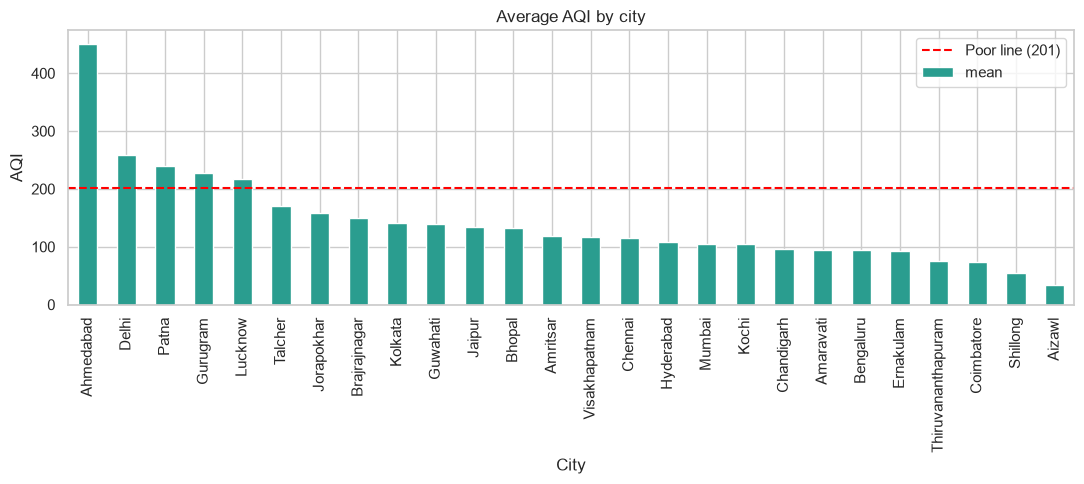

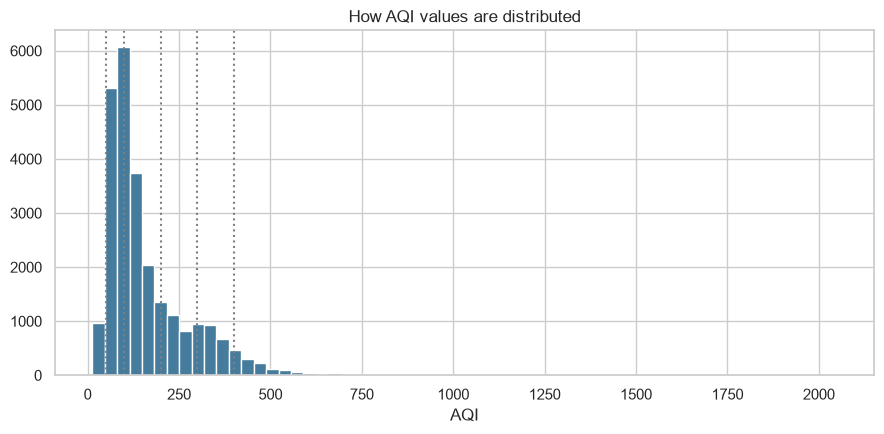

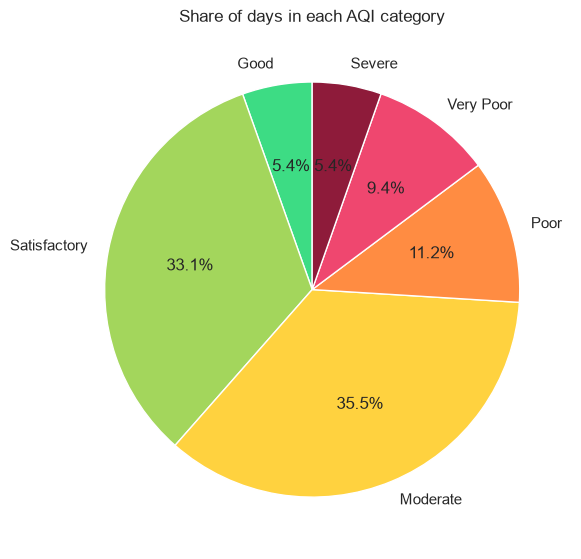

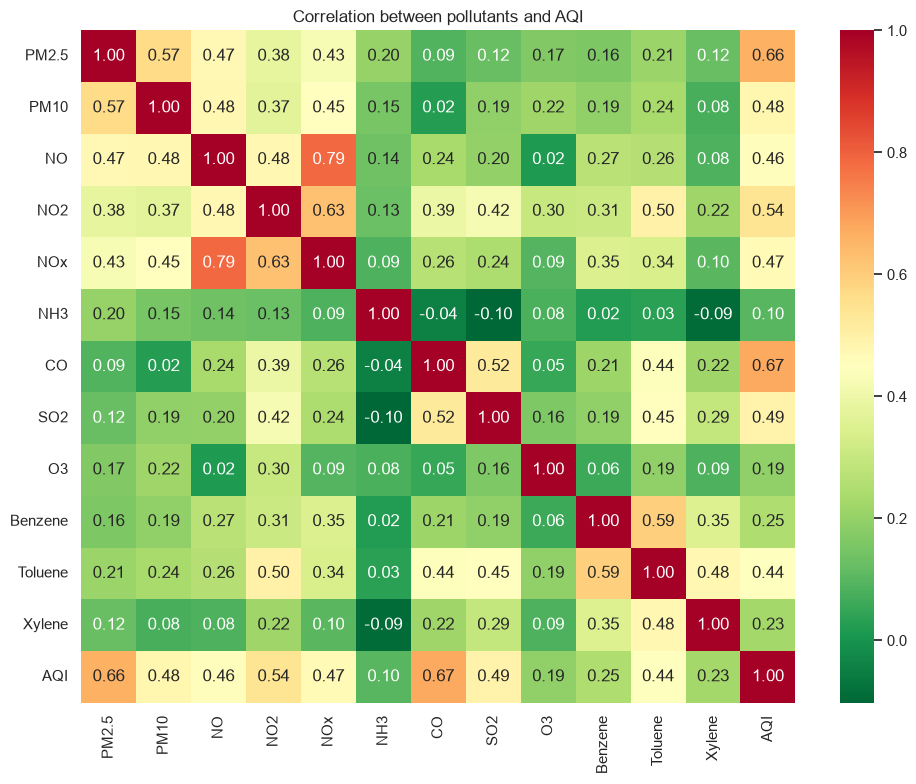

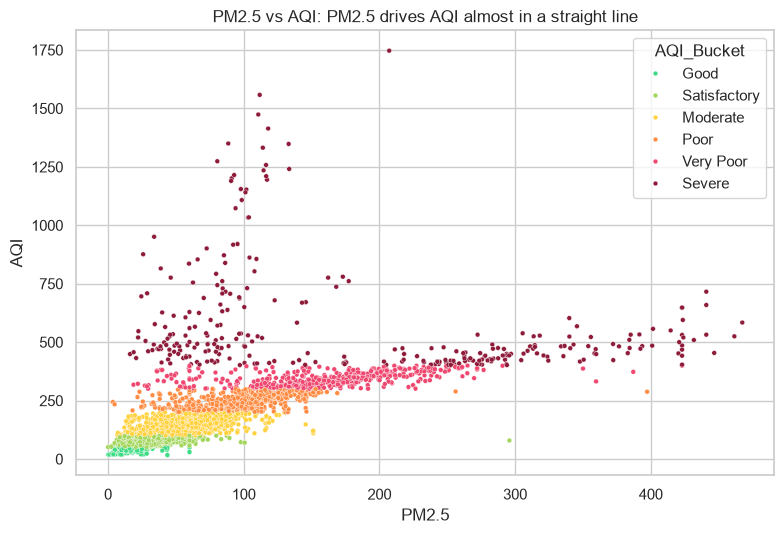

Correlation with AQI:
 AQI        1.00
CO         0.67
PM2.5      0.66
NO2        0.54
SO2        0.49
PM10       0.48
NOx        0.47
NO         0.46
Toluene    0.44
Benzene    0.25
Xylene     0.23
O3         0.19
NH3        0.10
Name: AQI, dtype: float64


In [7]:
AQI_COLORS = ["#3ddc84", "#a3d65c", "#ffd23f", "#ff8c42", "#ef476f", "#8e1b3a"]

fig, ax = plt.subplots(figsize=(11, 5))                     # 1) BAR
city_stats["mean"].plot.bar(ax=ax, color="#2a9d8f")
ax.axhline(POOR_LIMIT, color="red", ls="--", label="Poor line (201)")
ax.set_title("Average AQI by city"); ax.set_ylabel("AQI"); ax.legend()
save_fig(fig, "05a_bar_city_aqi")

fig, ax = plt.subplots(figsize=(9, 4.5))                    # 2) HISTOGRAM
ax.hist(df["AQI"], bins=60, color="#457b9d")
for v in [50, 100, 200, 300, 400]:
    ax.axvline(v, color="grey", ls=":")
ax.set_title("How AQI values are distributed"); ax.set_xlabel("AQI")
save_fig(fig, "05b_hist_aqi")

counts = df["AQI_Bucket"].value_counts().reindex(BUCKET_ORDER)  # 3) PIE
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(counts, labels=counts.index, autopct="%1.1f%%", colors=AQI_COLORS, startangle=90)
ax.set_title("Share of days in each AQI category")
save_fig(fig, "05c_pie_buckets")

corr = df[POLLUTANTS + ["AQI"]].corr()                       # 4) HEATMAP
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdYlGn_r", ax=ax)
ax.set_title("Correlation between pollutants and AQI")
save_fig(fig, "05d_heatmap_corr")

sample = df.sample(min(5000, len(df)), random_state=1)        # 5) SCATTER
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=sample, x="PM2.5", y="AQI", hue="AQI_Bucket",
                hue_order=BUCKET_ORDER, palette=AQI_COLORS, s=12, ax=ax)
ax.set_title("PM2.5 vs AQI: PM2.5 drives AQI almost in a straight line")
save_fig(fig, "05e_scatter_pm25_aqi")

RESULTS["corr_with_aqi"] = corr["AQI"].drop("AQI").sort_values(ascending=False).round(3).to_dict()
print("Correlation with AQI:\n", corr["AQI"].sort_values(ascending=False).round(2))

## Stage 5: Data Visualization
Each chart answers one question:
- **Bar:** Which city has the worst average AQI?
- **Histogram:** How are AQI values spread? (right-skewed)
- **Pie:** What share of days falls in each AQI category?
- **Heatmap:** Which pollutants move together?
- **Scatter:** How does PM2.5 relate to AQI? (almost a straight line)

In [6]:
num_cols = ["AQI", "PM2.5", "PM10", "NO2", "CO", "SO2", "O3"]
eda = pd.DataFrame({
    "mean": df[num_cols].mean(),
    "median": df[num_cols].median(),
    "mode": df[num_cols].round(0).mode().iloc[0],
    "variance": df[num_cols].var(),
    "std": df[num_cols].std(),
    "skewness": df[num_cols].skew(),
}).round(2)
print(eda)

df["AQI_z"] = stats.zscore(df["AQI"])
extreme_days = df.loc[df["AQI_z"].abs() > 3, ["City", "Date", "AQI", "AQI_z"]]
print(f"\nDays with |z| > 3: {len(extreme_days)}")
print(extreme_days.sort_values("AQI_z", ascending=False).head())

city_stats = (df.groupby("City")["AQI"].agg(["mean", "median", "std", "max"])
                .round(1).sort_values("mean", ascending=False))
print("\nMost polluted cities:\n", city_stats.head(8))
poor_share = (df["AQI"] >= POOR_LIMIT).mean()
print(f"\nShare of Poor-or-worse days: {poor_share:.1%}")

RESULTS["eda"] = {"table": eda.reset_index().rename(columns={"index": "variable"}).to_dict(orient="records"),
                  "z_extreme_days": int(len(extreme_days)),
                  "top_z": extreme_days.sort_values("AQI_z", ascending=False).head(10)
                                       .assign(Date=lambda d: d["Date"].dt.date.astype(str))
                                       .round(2).to_dict(orient="records"),
                  "city_stats": city_stats.reset_index().to_dict(orient="records"),
                  "poor_share": round(float(poor_share), 4)}

         mean  median   mode  variance     std  skewness
AQI    166.43  117.80  102.0  19809.85  140.75      3.38
PM2.5   66.43   49.62   60.0   3570.65   59.75      2.55
PM10   112.88   99.25   49.0   5785.43   76.06      2.09
NO2     28.47   21.73   10.0    573.90   23.96      2.26
CO       2.20    0.92    1.0     45.39    6.74      8.20
SO2     14.39    9.22    6.0    307.49   17.54      3.98
O3      34.64   30.86   30.0    455.29   21.34      1.19

Days with |z| > 3: 335
          City       Date     AQI      AQI_z
532  Ahmedabad 2018-02-19  2049.0  13.375797
523  Ahmedabad 2018-02-10  1917.0  12.437929
295  Ahmedabad 2016-07-14  1842.0  11.905049
435  Ahmedabad 2017-11-14  1747.0  11.230068
849  Ahmedabad 2019-01-03  1719.0  11.031126

Most polluted cities:
                mean  median    std     max
City                                      
Ahmedabad     451.4   381.0  310.0  2049.0
Delhi         258.8   257.0  119.8   716.0
Patna         240.4   215.0  121.4   619.0
Gurugram   

## Stage 4: Exploratory Data Analysis
- **Mean** = average, **Median** = middle value, **Mode** = most frequent value.
- Mean > median means the data is **right-skewed** (a long tail of very bad days).
- **Variance** = average squared distance from the mean; **Std** = its square root (same unit as the data).
- **z-score** = (value − mean) / std: how many standard deviations a day is from normal. |z| > 3 = very unusual.

   pollutant  upper_1.5IQR  outliers_1.5IQR  upper_3IQR  extreme_3IQR
0      PM2.5        155.31             2057      230.99           767
1       PM10        250.55             1573      366.12           485
2         NO         41.72             2455       63.34          1228
3        NO2         77.01             1149      116.19           276
4        NOx         74.88             1977      111.53           750
5        NH3         57.30             1249       85.30           505
6         CO          2.82             2370        4.17          1705
7        SO2         29.67             2549       44.04          1422
8         O3         85.09              747      124.58            88
9    Benzene          7.12             1912       11.21          1081
10   Toluene         17.44             3146       27.31          1937
11    Xylene          2.97             3335        4.11          2642


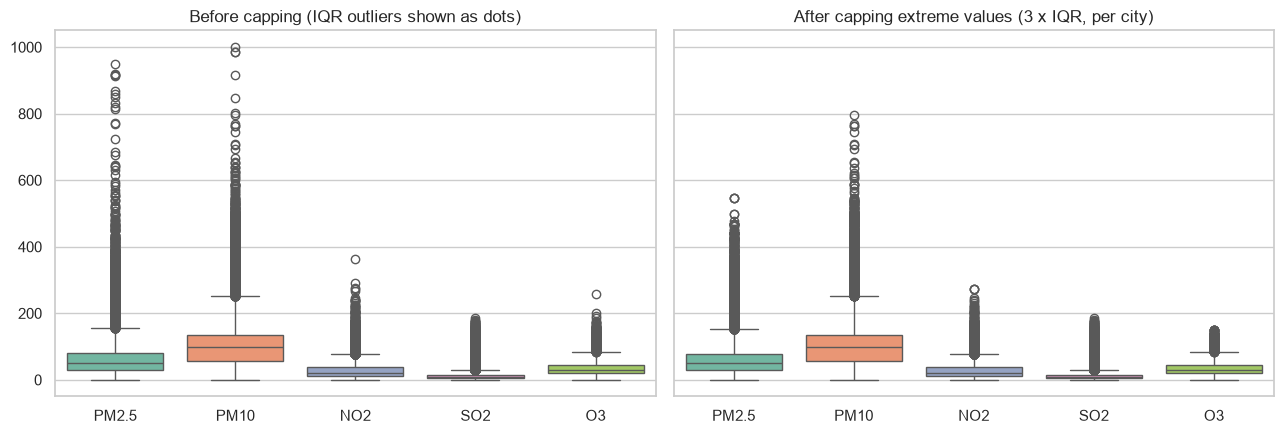

Saved cleaned data: (25572, 16)


In [5]:
def iqr_bounds(s, k):
    q1, q3 = s.quantile([0.25, 0.75])
    return q1 - k * (q3 - q1), q3 + k * (q3 - q1)


outlier_rows = []
for col in POLLUTANTS:
    lo15, hi15 = iqr_bounds(df[col], 1.5)
    lo3, hi3 = iqr_bounds(df[col], 3.0)
    outlier_rows.append({"pollutant": col,
                         "upper_1.5IQR": round(hi15, 2),
                         "outliers_1.5IQR": int(((df[col] < lo15) | (df[col] > hi15)).sum()),
                         "upper_3IQR": round(hi3, 2),
                         "extreme_3IQR": int(((df[col] < lo3) | (df[col] > hi3)).sum())})
outlier_table = pd.DataFrame(outlier_rows)
print(outlier_table)

before_box = df[["PM2.5", "PM10", "NO2", "SO2", "O3"]].copy()

for col in POLLUTANTS:
    lo = df.groupby("City")[col].transform(lambda s: iqr_bounds(s, 3.0)[0])
    hi = df.groupby("City")[col].transform(lambda s: iqr_bounds(s, 3.0)[1])
    df[col] = df[col].clip(lower=lo.clip(lower=0), upper=hi)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
sns.boxplot(data=before_box, ax=axes[0], palette="Set2")
axes[0].set_title("Before capping (IQR outliers shown as dots)")
sns.boxplot(data=df[["PM2.5", "PM10", "NO2", "SO2", "O3"]], ax=axes[1], palette="Set2")
axes[1].set_title("After capping extreme values (3 x IQR, per city)")
save_fig(fig, "03_boxplot_outliers")

RESULTS["outliers"] = outlier_table.to_dict(orient="records")
df["AQI_Bucket"] = pd.cut(df["AQI"], [-1, 50, 100, 200, 300, 400, 10_000], labels=BUCKET_ORDER)
df.to_csv(OUT / "clean_data.csv", index=False)
print("Saved cleaned data:", df.shape)

## Stage 3b: Preprocessing: Outliers (IQR + Box Plot)
**IQR = Q3 − Q1.** A value is an outlier if it is below Q1 − 1.5×IQR or above Q3 + 1.5×IQR. A box plot draws exactly this: the box runs from Q1 to Q3, the whiskers stop at 1.5×IQR, and the dots beyond them are outliers.
**Decision:** most 1.5×IQR outliers here are *real* winter smog days, the very days we want to predict. So we only **cap** values beyond the *extreme* fence (3×IQR, per city). This removes sensor glitches but keeps real bad days.

In [4]:
df = raw.drop_duplicates(["City", "Date"]).sort_values(["City", "Date"]).reset_index(drop=True)
before_missing = df[POLLUTANTS + ["AQI"]].isna().sum()

# 1) Fill short gaps by drawing a straight line between neighbouring days (per city)
df[POLLUTANTS] = (df.groupby("City")[POLLUTANTS]
                    .transform(lambda s: s.interpolate(limit=7, limit_direction="both")))
# 2) Fill what is left with that city's median, then the overall median
df[POLLUTANTS] = df.groupby("City")[POLLUTANTS].transform(lambda s: s.fillna(s.median()))
df[POLLUTANTS] = df[POLLUTANTS].fillna(df[POLLUTANTS].median())
# 3) AQI is our target: only fill tiny gaps (max 2 days), then drop rows still missing
df["AQI"] = df.groupby("City")["AQI"].transform(lambda s: s.interpolate(limit=2))
df = df.dropna(subset=["AQI"]).reset_index(drop=True)

after_missing = df[POLLUTANTS + ["AQI"]].isna().sum()
missing_table = pd.DataFrame({"before": before_missing, "after": after_missing})
print(missing_table)
RESULTS["missing"] = {"table": missing_table.to_dict(), "rows_after": int(len(df))}

         before  after
PM2.5      4598      0
PM10      11140      0
NO         3582      0
NO2        3585      0
NOx        4185      0
NH3       10328      0
CO         2059      0
SO2        3854      0
O3         4022      0
Benzene    5623      0
Toluene    8041      0
Xylene    18109      0
AQI        4681      0


## Stage 3a: Preprocessing: Missing Values
Done **inside each city**, because filling Delhi's gaps with Chennai's numbers would be wrong:
1. **Interpolate** short gaps (up to 7 days) by drawing a straight line between the days around the gap.
2. Fill longer gaps with the **city median** (the median is not pulled by extreme days).
3. **AQI is our target**, so we only fill tiny 2-day gaps and **drop** rows that are still empty. We never invent answers.

In [3]:
real_file = DATA_DIR / "city_day.csv"
sample_file = DATA_DIR / "city_day_sample.csv"
if real_file.exists():
    DATA_FILE, USING_REAL = real_file, True
else:
    if not sample_file.exists():
        import runpy
        runpy.run_path(str(DATA_DIR / "make_sample_data.py"))
    DATA_FILE, USING_REAL = sample_file, False
    print("NOTE: real city_day.csv not found, using the practice copy.")

raw = pd.read_csv(DATA_FILE, parse_dates=["Date"])
print("Loaded:", DATA_FILE.name, "| rows:", raw.shape[0], "| columns:", raw.shape[1])
print(raw.head())

missing_pct = (raw.isna().mean() * 100).round(1).sort_values(ascending=False)
print("\nMissing values (%):\n", missing_pct)

problems_found = {
    "rows": int(len(raw)),
    "cities": int(raw["City"].nunique()),
    "date_range": [str(raw["Date"].min().date()), str(raw["Date"].max().date())],
    "duplicate_rows": int(raw.duplicated(["City", "Date"]).sum()),
    "missing_pct": missing_pct.to_dict(),
    "rows_per_city": raw["City"].value_counts().to_dict(),
    "aqi_missing_rows": int(raw["AQI"].isna().sum()),
}
RESULTS["data"] = {"source": "Kaggle: Air Quality Data in India (2015-2020), CPCB stations",
                   "url": "https://www.kaggle.com/datasets/rohanrao/air-quality-data-in-india",
                   "file": DATA_FILE.name, "real_data": USING_REAL, **problems_found}
print(f"\nCities: {problems_found['cities']}, duplicates: {problems_found['duplicate_rows']}, "
      f"AQI missing: {problems_found['aqi_missing_rows']}")

Loaded: city_day.csv | rows: 29531 | columns: 16
        City       Date  PM2.5  PM10     NO    NO2    NOx  NH3     CO    SO2  \
0  Ahmedabad 2015-01-01    NaN   NaN   0.92  18.22  17.15  NaN   0.92  27.64   
1  Ahmedabad 2015-01-02    NaN   NaN   0.97  15.69  16.46  NaN   0.97  24.55   
2  Ahmedabad 2015-01-03    NaN   NaN  17.40  19.30  29.70  NaN  17.40  29.07   
3  Ahmedabad 2015-01-04    NaN   NaN   1.70  18.48  17.97  NaN   1.70  18.59   
4  Ahmedabad 2015-01-05    NaN   NaN  22.10  21.42  37.76  NaN  22.10  39.33   

       O3  Benzene  Toluene  Xylene  AQI AQI_Bucket  
0  133.36     0.00     0.02    0.00  NaN        NaN  
1   34.06     3.68     5.50    3.77  NaN        NaN  
2   30.70     6.80    16.40    2.25  NaN        NaN  
3   36.08     4.43    10.14    1.00  NaN        NaN  
4   39.31     7.01    18.89    2.78  NaN        NaN  

Missing values (%):
 Xylene        61.3
PM10          37.7
NH3           35.0
Toluene       27.2
Benzene       19.0
AQI           15.9
AQI_Bucket

## Stage 2: Data Collection
**Source:** Kaggle "Air Quality Data in India (2015-2020)", collected from CPCB (Central Pollution Control Board) stations. File: `city_day.csv`, with one row per city per day: 12 pollutants + AQI + AQI_Bucket.
We load it and list the **problems found**: missing values, duplicates, uneven coverage per city, and rows with no AQI.

In [2]:
PROBLEM = {
    "question": "Will tomorrow's AQI in this city be 'Poor' or worse (AQI >= 201)?",
    "type": "Binary classification (1 = Poor or worse tomorrow, 0 = otherwise)",
    "descriptive": "What happened? Average AQI per city, worst months, pollutant trends.",
    "predictive": "What will happen? Probability that tomorrow's AQI crosses 200.",
    "prescriptive": "What should we do? Issue a health alert, close schools, restrict trucks.",
    "industry": "Public health departments, smart-city control rooms, hospitals "
                "(prepare for asthma cases), schools, air purifier / mask companies.",
    "ethics": [
        "Location bias: Monitoring stations are concentrated in big cities, so small towns "
        "and rural areas are under-represented.",
        "Missing data: Sensors fail more in some cities than others, so the gaps are not "
        "random and can bias the model.",
        "Missed alerts: A false negative means vulnerable people (children, elderly, "
        "asthma patients) get no warning, so recall matters most.",
        "Privacy: The data is city-level and public (CPCB), so no personal data is used. "
        "Linking it to individual health records would need consent and anonymisation.",
        "False alarms: Too many wrong alerts cause panic, economic loss and alert fatigue.",
    ],
}
RESULTS["problem"] = PROBLEM
for k, v in PROBLEM.items():
    print(f"{k.upper():13s}:", v if isinstance(v, str) else "\n  - " + "\n  - ".join(v))

QUESTION     : Will tomorrow's AQI in this city be 'Poor' or worse (AQI >= 201)?
TYPE         : Binary classification (1 = Poor or worse tomorrow, 0 = otherwise)
DESCRIPTIVE  : What happened? Average AQI per city, worst months, pollutant trends.
PREDICTIVE   : What will happen? Probability that tomorrow's AQI crosses 200.
PRESCRIPTIVE : What should we do? Issue a health alert, close schools, restrict trucks.
INDUSTRY     : Public health departments, smart-city control rooms, hospitals (prepare for asthma cases), schools, air purifier / mask companies.
ETHICS       : 
  - Location bias: Monitoring stations are concentrated in big cities, so small towns and rural areas are under-represented.
  - Missing data: Sensors fail more in some cities than others, so the gaps are not random and can bias the model.
  - Missed alerts: A false negative means vulnerable people (children, elderly, asthma patients) get no warning, so recall matters most.
  - Privacy: The data is city-level and public (C

## Stage 1: Problem Definition & Ethics
**Problem:** Every winter Indian cities choke on smog. If we can predict *today* that *tomorrow* will be Poor (AQI ≥ 201), hospitals, schools and parents can prepare.
- **Descriptive** = what happened, **Predictive** = what will happen, **Prescriptive** = what to do.
- Task: **binary classification** (1 = tomorrow Poor or worse, 0 = not).
- Ethics: stations are biased toward big cities, missing data is not random, and a missed alert (false negative) can hurt vulnerable people, so **recall** matters. The data is public and city-level, so there's no personal privacy risk.

In [1]:
%matplotlib inline
import json
import warnings
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

try:
    ROOT = Path(__file__).resolve().parent
except NameError:
    ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
OUT = ROOT / "outputs"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

RESULTS = {}
POLLUTANTS = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3",
              "Benzene", "Toluene", "Xylene"]
BUCKET_ORDER = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
POOR_LIMIT = 201


def save_fig(fig, name):
    """Save a chart into outputs/figures and show it."""
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", dpi=120)
    if "inline" in matplotlib.get_backend().lower():
        plt.show()
    plt.close(fig)


print("Project folder:", ROOT)

Project folder: c:\Users\Gurnoor Kaur\Desktop\air-quality


# Air Quality Health Alert Predictor (India)
## Setup: load libraries and create the outputs folder